# Actividad 1 — Análisis de la rotación del inventario por película y tienda.

Métricas principales:

* **Índice de rotación:** cantidad de alquileres / cantidad de copias disponibles.
* **Promedio de días de ociosidad:** cantidad de días entre la devolución de una copia y su siguiente alquiler.

## 1. Configuración del entorno

In [1]:
import sys
import pandas as pd
import numpy as np

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SQL_ACTIVIDAD_1 = PROJECT_ROOT / "sql" / "actividad_1"
sys.path.insert(0, str(PROJECT_ROOT))

from config_conexion import get_engine

## 2. Lectura del conjunto de trabajo

La consulta utilizada para obtener los datos se encuentra en el archivo `sql/actividad_1/conjunto_trabajo.sql`.

Esta consulta devuelve los datos necesarios de inventario y alquileres sin calcular previamente las métricas.

In [2]:
sql_path = SQL_ACTIVIDAD_1 / "conjunto_trabajo.sql"

with open(sql_path, "r", encoding="utf-8") as archivo:
    consulta = archivo.read()

print(consulta)

SELECT
    i.inventario_id AS id,
    i.pelicula_id AS pelicula,
    i.tienda_id AS tienda,
    a.alquiler_id AS alquiler,
    a.fecha_alquiler AS fecha,
    a.fecha_devolucion AS devolucion
FROM inventario AS i
LEFT JOIN alquiler AS a
    ON i.inventario_id = a.inventario_id;


## 3. Carga de datos desde SQL Server

In [3]:
engine = get_engine()

with engine.connect() as conexion:
    df = pd.read_sql(consulta, conexion)

df.head()

,id,pelicula,tienda,alquiler,fecha,devolucion
0,367,80,1,1.0,2005-05-24 22:53:30,2005-05-26 22:04:30
1,1525,333,2,2.0,2005-05-24 22:54:33,2005-05-28 19:40:33
2,1711,373,2,3.0,2005-05-24 23:03:39,2005-06-01 22:12:39
3,2452,535,1,4.0,2005-05-24 23:04:41,2005-06-03 01:43:41
4,2079,450,2,5.0,2005-05-24 23:05:21,2005-06-02 04:33:21


## 4. Obtención de la devolución anterior

Para calcular los días de ociosidad es necesario conocer cuándo fue devuelta una copia antes de volver a ser alquilada.

Primero se ordenan los registros por `id` de inventario y fecha de alquiler. Luego se agrupan los registros por copia física mediante `groupby("id")`.

Sobre la columna `devolucion` se aplica `shift(1)`, desplazando las devoluciones una posición dentro de cada copia. De esta manera, cada alquiler puede conocer la fecha de devolución del alquiler inmediatamente anterior.

Esta operación es equivalente conceptualmente a utilizar `LAG(fecha_devolucion)` particionado por inventario en SQL Server.

In [4]:
df = df.sort_values(
    by=["id", "fecha"]
).copy()

df["devolucion_anterior"] = (
    df.groupby("id")["devolucion"]
      .shift(1)
)

df[
    ["id", "alquiler", "fecha", "devolucion", "devolucion_anterior"]
].head(10)

,id,alquiler,fecha,devolucion,devolucion_anterior
4860,1,4863.0,2005-07-08 19:03:15,2005-07-11 21:29:15,NaT
11428,1,11433.0,2005-08-02 20:13:10,2005-08-11 21:35:10,2005-07-11 21:29:15
14709,1,14714.0,2005-08-21 21:27:43,2005-08-30 22:26:43,2005-08-11 21:35:10
970,2,972.0,2005-05-30 20:21:07,2005-06-06 00:36:07,NaT
2115,2,2117.0,2005-06-17 20:24:00,2005-06-23 17:45:00,2005-06-06 00:36:07
4184,2,4187.0,2005-07-07 10:41:31,2005-07-11 06:25:31,2005-06-23 17:45:00
9444,2,9449.0,2005-07-30 22:02:34,2005-08-06 02:09:34,2005-07-11 06:25:31
15448,2,15453.0,2005-08-23 01:01:01,2005-08-30 20:08:01,2005-08-06 02:09:34
10121,3,10126.0,2005-07-31 21:36:07,2005-08-03 23:59:07,NaT
15416,3,15421.0,2005-08-22 23:56:37,2005-08-25 18:58:37,2005-08-03 23:59:07


## 5. Cálculo de los días de ociosidad

Los días de ociosidad representan el tiempo durante el cual una copia permaneció disponible entre dos alquileres consecutivos.

Se calculan restando la devolución del alquiler anterior a la fecha del alquiler actual:

**días de ociosidad = fecha del nuevo alquiler - devolución anterior**

El primer alquiler de cada copia no posee una devolución anterior, por lo que su valor de ociosidad queda como `NaN`. Este valor no debe reemplazarse por cero, ya que cero indicaría que la copia fue alquilada nuevamente el mismo día.

In [5]:
# DATEDIFF(DAY, inicio, fin) cuenta cambios de fecha de calendario.
# Se normalizan las horas para mantener la misma definicion en pandas.
df["dias_ociosidad"] = (
    df["fecha"].dt.normalize() - df["devolucion_anterior"].dt.normalize()
).dt.days

df[
    ["id", "pelicula", "tienda", "fecha", "devolucion_anterior", "dias_ociosidad"]
].head(10)

,id,pelicula,tienda,fecha,devolucion_anterior,dias_ociosidad
4860,1,1,1,2005-07-08 19:03:15,NaT,NaN
11428,1,1,1,2005-08-02 20:13:10,2005-07-11 21:29:15,22.0
14709,1,1,1,2005-08-21 21:27:43,2005-08-11 21:35:10,10.0
970,2,1,1,2005-05-30 20:21:07,NaT,NaN
2115,2,1,1,2005-06-17 20:24:00,2005-06-06 00:36:07,11.0
4184,2,1,1,2005-07-07 10:41:31,2005-06-23 17:45:00,14.0
9444,2,1,1,2005-07-30 22:02:34,2005-07-11 06:25:31,19.0
15448,2,1,1,2005-08-23 01:01:01,2005-08-06 02:09:34,17.0
10121,3,1,1,2005-07-31 21:36:07,NaT,NaN
15416,3,1,1,2005-08-22 23:56:37,2005-08-03 23:59:07,19.0


## 6. Promedio de días de ociosidad

Una vez calculada la ociosidad entre alquileres, los registros se agrupan por película y tienda.

Para cada combinación se obtiene la media de `dias_ociosidad` mediante `mean`.

Los valores `NaN`, correspondientes principalmente al primer alquiler de cada copia, no participan del cálculo del promedio (`mean` de pandas los ignora).

In [6]:
ociosidad_promedio = (
    df.groupby(["pelicula", "tienda"], as_index=False)
      .agg(
          promedio_dias_ociosidad=("dias_ociosidad", "mean")
      )
)

ociosidad_promedio.head(10)

,pelicula,tienda,promedio_dias_ociosidad
0,1,1,16.250000
1,1,2,16.250000
2,2,2,59.750000
3,3,2,17.500000
4,4,1,16.444444
5,4,2,44.142857
6,5,2,33.555556
7,6,1,15.125000
8,6,2,13.571429
9,7,1,14.250000


## 7. Cálculo del índice de rotación

El índice de rotación permite relacionar la cantidad de alquileres con la cantidad de copias disponibles de una película en cada tienda.

La fórmula utilizada es:

**índice de rotación = cantidad de alquileres / cantidad de copias**

Para obtener la cantidad de copias se utiliza `nunique` sobre el identificador de inventario. Esto es necesario porque una misma copia puede aparecer varias veces en el conjunto de datos debido a sus distintos alquileres.

Para obtener la cantidad de alquileres se utiliza `count` sobre la columna `alquiler`. Los valores nulos no se cuentan, por lo que las copias que nunca fueron alquiladas permanecen en el inventario pero no incrementan la cantidad de alquileres.

In [7]:
rotacion = (
    df.groupby(["pelicula", "tienda"], as_index=False)
      .agg(
          cantidad_copias=("id", "nunique"),
          cantidad_alquileres=("alquiler", "count")
      )
)

rotacion["indice_rotacion"] = (
    rotacion["cantidad_alquileres"]
    / rotacion["cantidad_copias"]
)

rotacion.head(10)

,pelicula,tienda,cantidad_copias,cantidad_alquileres,indice_rotacion
0,1,1,4,12,3.000000
1,1,2,4,11,2.750000
2,2,2,3,7,2.333333
3,3,2,4,12,3.000000
4,4,1,4,13,3.250000
5,4,2,3,10,3.333333
6,5,2,3,12,4.000000
7,6,1,3,11,3.666667
8,6,2,3,10,3.333333
9,7,1,2,6,3.000000


## 8. Resultado de las métricas calculadas con pandas

Finalmente se combinan los resultados de rotación y ociosidad mediante las columnas `pelicula` y `tienda`.

El DataFrame resultante contiene, para cada película y tienda:

- cantidad de copias;
- cantidad de alquileres;
- índice de rotación;
- promedio de días de ociosidad.

Este resultado podrá compararse posteriormente con las mismas métricas calculadas directamente en T-SQL.

In [8]:
resultado_pandas = rotacion.merge(
    ociosidad_promedio,
    on=["pelicula", "tienda"],
    how="left"
)

resultado_pandas.head(10)

,pelicula,tienda,cantidad_copias,cantidad_alquileres,indice_rotacion,promedio_dias_ociosidad
0,1,1,4,12,3.000000,16.250000
1,1,2,4,11,2.750000,16.250000
2,2,2,3,7,2.333333,59.750000
3,3,2,4,12,3.000000,17.500000
4,4,1,4,13,3.250000,16.444444
5,4,2,3,10,3.333333,44.142857
6,5,2,3,12,4.000000,33.555556
7,6,1,3,11,3.666667,15.125000
8,6,2,3,10,3.333333,13.571429
9,7,1,2,6,3.000000,14.250000


## 9. Ejecución de la métrica en T-SQL

La misma métrica se ejecuta en SQL Server desde `sql/actividad_1/metricas_rotacion.sql`, sin copiar la consulta dentro del notebook. SQL Server usa `LAG` y agrupa por película y tienda. Se mide la consulta completa para informar su tiempo por separado.

In [9]:
from time import perf_counter

consulta_metricas = (SQL_ACTIVIDAD_1 / 'metricas_rotacion.sql').read_text(encoding='utf-8')
tiempos_sql = []
for _ in range(10):
    inicio = perf_counter()
    with engine.connect() as conexion:
        resultado_sql = pd.read_sql(consulta_metricas, conexion)
    tiempos_sql.append(perf_counter() - inicio)

resultado_sql.head() # type: ignore

,pelicula,tienda,cantidad_copias,cantidad_alquileres,indice_rotacion,promedio_dias_ociosidad
0,1,1,4,12,3.000000,16.250000
1,1,2,4,11,2.750000,16.250000
2,2,2,3,7,2.333333,59.750000
3,3,2,4,12,3.000000,17.500000
4,4,1,4,13,3.250000,16.444444


## 10. Comparación entre T-SQL y pandas

Los resultados se unen por `pelicula` y `tienda`. Los conteos se comparan exactamente y las métricas decimales se validan antes de aplicar formato de presentación.

### Hallazgo sobre redondeo

En una comparación inicial se observaron diferencias de 0,01 en algunos promedios de días de ociosidad. La revisión mostró que la fórmula era equivalente, pero ambas implementaciones reducían el promedio a dos decimales antes de compararlo. En valores situados en un punto intermedio, SQL Server y pandas pueden resolver el redondeo de manera diferente.

Por ese motivo, `metricas_rotacion.sql` conserva doce decimales y pandas mantiene los valores sin `.round(2)`. La validación usa `assert_frame_equal` con una tolerancia absoluta de `1e-9`, limitada a la representación numérica de punto flotante. El formato de dos decimales queda reservado para una eventual presentación, no para calcular ni validar.

In [10]:
claves = ["pelicula", "tienda"]

columnas_decimales = [
    "indice_rotacion",
    "promedio_dias_ociosidad"
]

sql_comparacion = (
    resultado_sql
    .sort_values(claves)
    .reset_index(drop=True)
    .copy()
)

pandas_comparacion = (
    resultado_pandas
    .sort_values(claves)
    .reset_index(drop=True)
    .copy()
)

for columna in columnas_decimales:
    sql_comparacion[columna] = pd.to_numeric(
        sql_comparacion[columna],
        errors="raise"
    ).astype(float)

    pandas_comparacion[columna] = pd.to_numeric(
        pandas_comparacion[columna],
        errors="raise"
    ).astype(float)

validacion_equivalente = False

try:
    pd.testing.assert_frame_equal(
        sql_comparacion,
        pandas_comparacion,
        check_dtype=False,
        check_exact=False,
        rtol=0,
        atol=1e-9
    )

    validacion_equivalente = True
    print("VALIDACIÓN EXITOSA")
    print("-" * 45)
    print(f"Filas comparadas:        {len(sql_comparacion)}")
    print(f"Columnas comparadas:     {len(sql_comparacion.columns)}")
    print(f"Grupos película/tienda:  {len(sql_comparacion)}")
    print(f"Tolerancia numérica:     1e-9")
    print()
    print("Resultados:")
    print("Cantidad de copias coincide")
    print("Cantidad de alquileres coincide")
    print("Índice de rotación coincide")
    print("Promedio de ociosidad coincide")
    print()
    print("Conclusión:")
    print("T-SQL y pandas producen resultados equivalentes.")

except AssertionError as error:
    print("VALIDACIÓN FALLIDA")
    print("-" * 45)
    print("Se encontraron diferencias entre T-SQL y pandas.")
    print()
    print(error)

VALIDACIÓN EXITOSA
---------------------------------------------
Filas comparadas:        1521
Columnas comparadas:     6
Grupos película/tienda:  1521
Tolerancia numérica:     1e-9

Resultados:
Cantidad de copias coincide
Cantidad de alquileres coincide
Índice de rotación coincide
Promedio de ociosidad coincide

Conclusión:
T-SQL y pandas producen resultados equivalentes.


## 11. Medición de tiempos

El tiempo de T-SQL incluye ejecutar la consulta agregada y recibir su resultado desde SQL Server. El de pandas mide solamente ordenar, aplicar `groupby`/`shift` y calcular/agrupar métricas sobre el DataFrame ya cargado. Se hacen tres repeticiones y se informa el promedio; no permiten sacar conclusiones absolutas de rendimiento.

In [11]:
def calcular_metricas_pandas(datos_crudos):
    datos = datos_crudos.sort_values(['id', 'fecha']).copy()
    datos['devolucion_anterior'] = datos.groupby('id')['devolucion'].shift(1)
    datos['dias_ociosidad'] = (datos['fecha'].dt.normalize() - datos['devolucion_anterior'].dt.normalize()).dt.days
    ociosidad = datos.groupby(['pelicula', 'tienda'], as_index=False).agg(promedio_dias_ociosidad=('dias_ociosidad', 'mean'))
    rotacion_temporal = datos.groupby(['pelicula', 'tienda'], as_index=False).agg(cantidad_copias=('id', 'nunique'), cantidad_alquileres=('alquiler', 'count'))
    rotacion_temporal['indice_rotacion'] = rotacion_temporal['cantidad_alquileres'] / rotacion_temporal['cantidad_copias']
    return rotacion_temporal.merge(ociosidad, on=['pelicula', 'tienda'], how='left')

tiempos_pandas = []
for _ in range(10):
    inicio = perf_counter()
    resultado_pandas_temporal = calcular_metricas_pandas(df.drop(columns=['devolucion_anterior', 'dias_ociosidad']))
    tiempos_pandas.append(perf_counter() - inicio)
assert resultado_pandas_temporal.equals(resultado_pandas) # type: ignore
tabla_tiempos = pd.DataFrame({'implementacion': ['T-SQL', 'pandas'], 'promedio_segundos': [np.mean(tiempos_sql), np.mean(tiempos_pandas)], 'minimo_segundos': [np.min(tiempos_sql), np.min(tiempos_pandas)], 'repeticiones': [len(tiempos_sql), len(tiempos_pandas)]})
tabla_tiempos

,implementacion,promedio_segundos,minimo_segundos,repeticiones
0,T-SQL,0.050100,0.047822,10
1,pandas,0.013146,0.012338,10


## 12. Controles de calidad

Una copia nunca alquilada es una unidad física existente en inventario sin alquileres. Una película sin copias es un título del catálogo sin disponibilidad física. Como el conjunto de trabajo parte de inventario, el segundo caso requiere una consulta separada sobre `pelicula`.

In [12]:
def leer_sql(nombre_archivo):
    consulta = (SQL_ACTIVIDAD_1 / nombre_archivo).read_text(encoding='utf-8')
    with engine.connect() as conexion:
        return pd.read_sql(consulta, conexion)

copias_nunca_alquiladas = leer_sql('copias_nunca_alquiladas.sql')
peliculas_sin_copias = leer_sql('peliculas_sin_copias.sql')
print(f'Copias de inventario nunca alquiladas: {len(copias_nunca_alquiladas)}')
display(copias_nunca_alquiladas.head())
print(f'Películas del catálogo sin copias: {len(peliculas_sin_copias)}')
display(peliculas_sin_copias.head())

Copias de inventario nunca alquiladas: 1


,id,pelicula,tienda
0,5,1,2


Películas del catálogo sin copias: 42


,pelicula,titulo
0,14,ALICE FANTASIA
1,33,APOLLO TEEN
2,36,ARGONAUTS TOWN
3,38,ARK RIDGEMONT
4,41,ARSENIC INDEPENDENCE


## 13. Gráficos de rotación

Se incorporan los títulos desde `pelicula`. El primer gráfico conserva el ranking obligatorio de 15 combinaciones con mayor y menor rotación, pero declara cómo resuelve los empates y agrega alquileres, copias y ociosidad en cada barra.

En esta ejecución, los extremos tienen muchos empates: 49 combinaciones alcanzan el máximo de 5,00 y 33 el mínimo de 2,00. Por eso las barras de cada extremo tienen la misma longitud y no permiten establecer un orden interno útil; el gráfico se incluye porque es un requisito de la consigna y documenta qué títulos integran cada grupo.

Como complemento orientado a la decisión de negocio, el segundo gráfico compara la misma película entre Tienda 1 y Tienda 2. Ordena por la brecha absoluta de rotación y permite detectar títulos cuyo uso relativo cambia entre sucursales; esos son los casos que pueden justificar analizar una redistribución de stock.

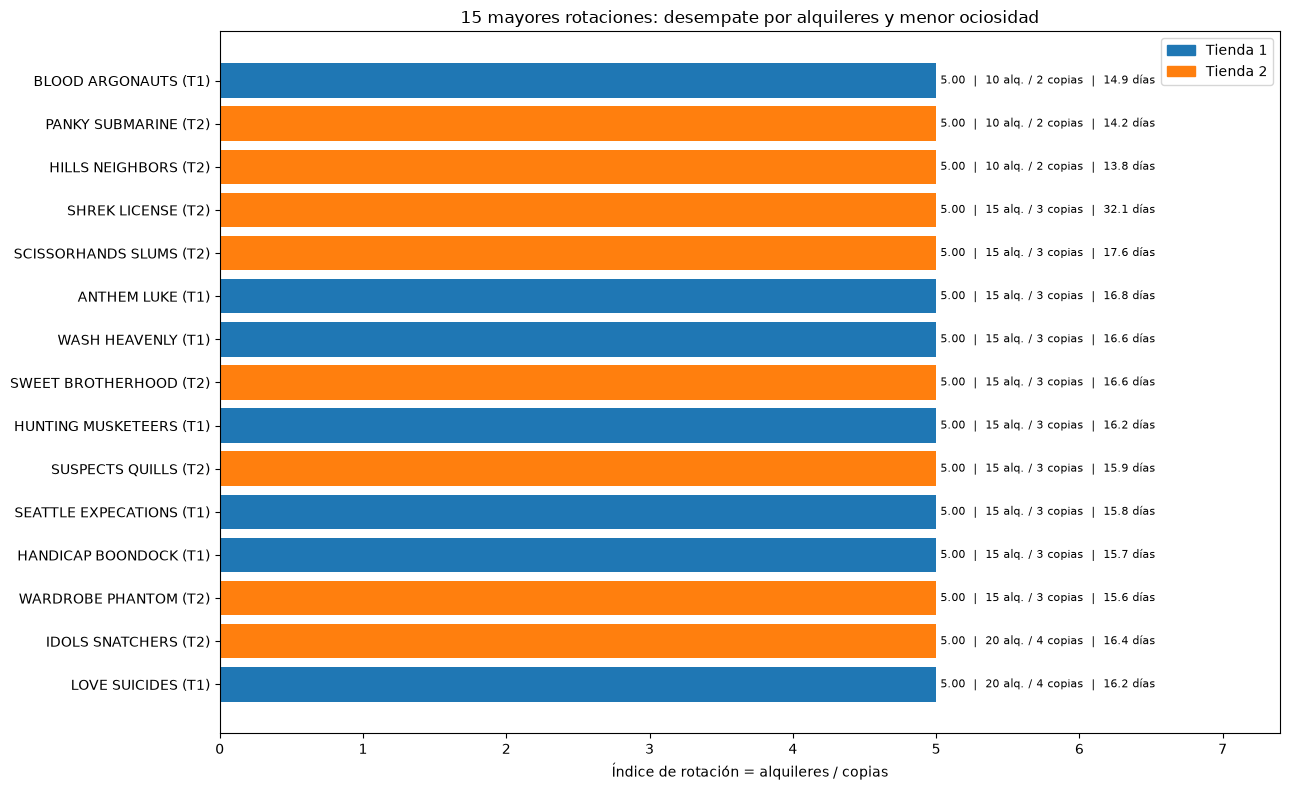

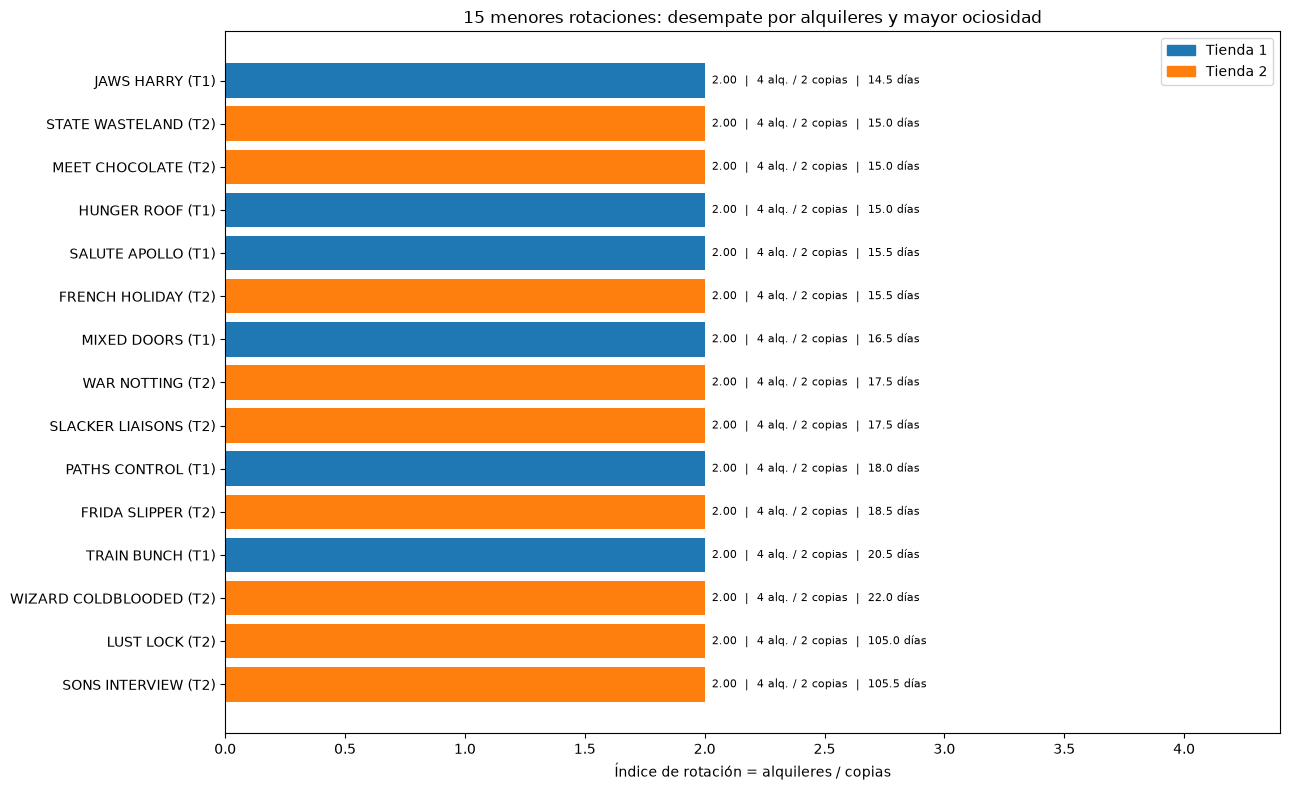

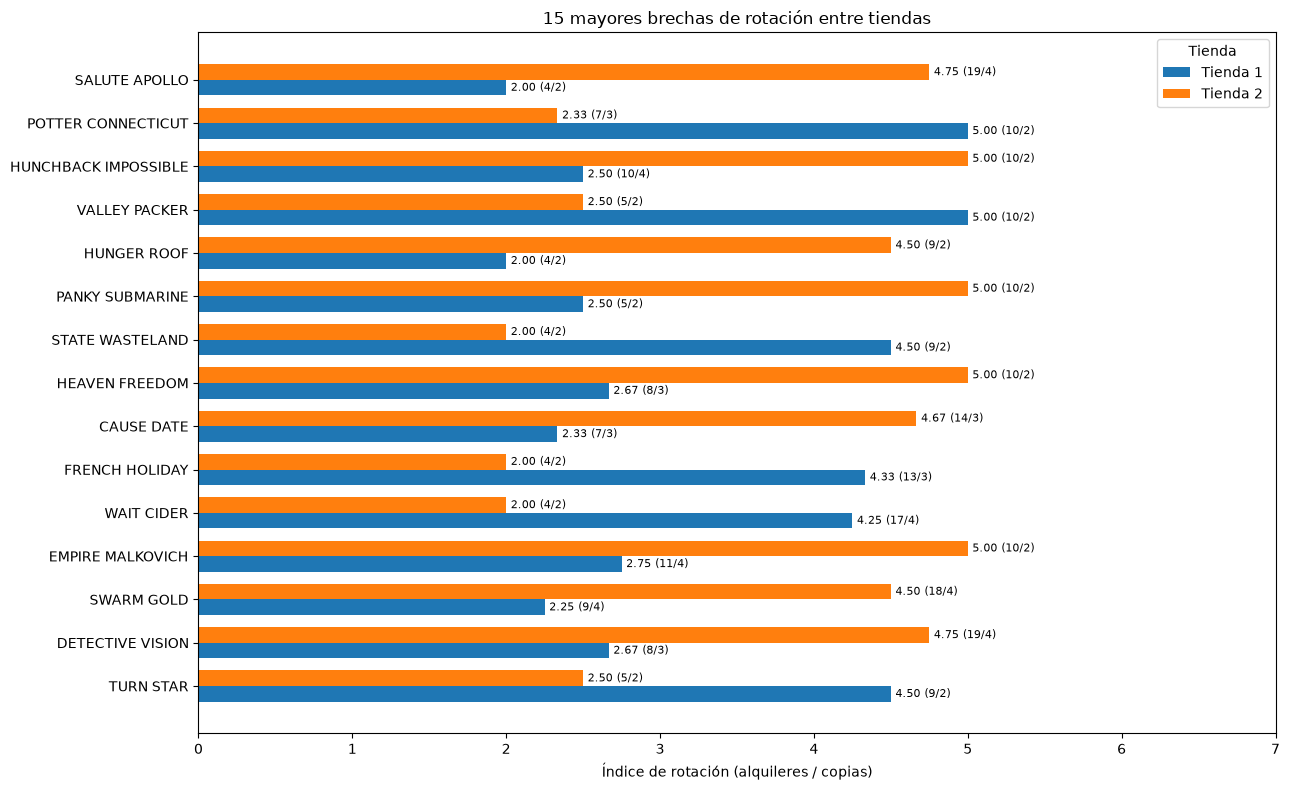

,,rotacion_tienda_1,rotacion_tienda_2,brecha_rotacion
pelicula,titulo,,,
916,TURN STAR,4.500000,2.500000,2.000000
228,DETECTIVE VISION,2.666667,4.750000,2.083333
870,SWARM GOLD,2.250000,4.500000,2.250000
280,EMPIRE MALKOVICH,2.750000,5.000000,2.250000
953,WAIT CIDER,4.250000,2.000000,2.250000
336,FRENCH HOLIDAY,4.333333,2.000000,2.333333
129,CAUSE DATE,2.333333,4.666667,2.333333
410,HEAVEN FREEDOM,2.666667,5.000000,2.333333
842,STATE WASTELAND,4.500000,2.000000,2.500000


In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

titulos = leer_sql("titulos_peliculas.sql")
rotacion_con_titulos = resultado_pandas.merge(titulos, on="pelicula", how="left")
colores_tienda = {1: "#1f77b4", 2: "#ff7f0e"}
directorio_graficos = PROJECT_ROOT / "graficos" / "actividad_1"
directorio_graficos.mkdir(exist_ok=True)


def seleccionar_extremo(datos, mayor=True):
    # El criterio secundario evita que un empate se resuelva por el orden de filas.
    return datos.sort_values(
        ["indice_rotacion", "cantidad_alquileres", "promedio_dias_ociosidad", "titulo"],
        ascending=[not mayor, not mayor, mayor, True],
    ).head(15)


def grafico_extremos(datos, titulo, ruta):
    datos = datos.sort_values("indice_rotacion")
    etiquetas = datos.apply(
        lambda fila: f"{fila['titulo']} (T{fila['tienda']})", axis=1
    )
    figura, eje = plt.subplots(figsize=(13, 8))
    barras = eje.barh(
        etiquetas, datos["indice_rotacion"], color=datos["tienda"].map(colores_tienda)
    )
    for barra, (_, fila) in zip(barras, datos.iterrows()):
        etiqueta = f"{fila['indice_rotacion']:.2f}  |  {fila['cantidad_alquileres']} alq. / {fila['cantidad_copias']} copias  |  {fila['promedio_dias_ociosidad']:.1f} días"
        eje.text(
            barra.get_width() + 0.03,
            barra.get_y() + barra.get_height() / 2,
            etiqueta,
            va="center",
            fontsize=8,
        )
    eje.set(
        title=titulo,
        xlabel="Índice de rotación = alquileres / copias",
        xlim=(0, datos["indice_rotacion"].max() + 2.4),
    )
    eje.legend(
        handles=[
            Patch(color=color, label=f"Tienda {tienda}")
            for tienda, color in colores_tienda.items()
        ]
    )
    figura.tight_layout()
    figura.savefig(ruta, dpi=150, bbox_inches="tight")
    plt.show()


mayores = seleccionar_extremo(rotacion_con_titulos, mayor=True)
menores = seleccionar_extremo(rotacion_con_titulos, mayor=False)
grafico_extremos(
    mayores,
    "15 mayores rotaciones: desempate por alquileres y menor ociosidad",
    directorio_graficos / "rotacion_mayor.png",
)
grafico_extremos(
    menores,
    "15 menores rotaciones: desempate por alquileres y mayor ociosidad",
    directorio_graficos / "rotacion_menor.png",
)

# Oportunidades: se comparan solamente películas que tienen copias en ambas tiendas.
por_tienda = rotacion_con_titulos.pivot_table(
    index=["pelicula", "titulo"],
    columns="tienda",
    values=["indice_rotacion", "cantidad_copias", "cantidad_alquileres"],
    aggfunc="first",
)
por_tienda = por_tienda.dropna(
    subset=[("indice_rotacion", 1), ("indice_rotacion", 2)]
).copy()
por_tienda["brecha_rotacion"] = (
    por_tienda[("indice_rotacion", 1)] - por_tienda[("indice_rotacion", 2)]
).abs()
oportunidades = (
    por_tienda.sort_values("brecha_rotacion", ascending=False)
    .head(15)
    .sort_values("brecha_rotacion")
)

figura, eje = plt.subplots(figsize=(13, 8))
posicion = np.arange(len(oportunidades))
altura = 0.36
barras_1 = eje.barh(
    posicion - altura / 2,
    oportunidades[("indice_rotacion", 1)],
    altura,
    color=colores_tienda[1],
    label="Tienda 1",
)
barras_2 = eje.barh(
    posicion + altura / 2,
    oportunidades[("indice_rotacion", 2)],
    altura,
    color=colores_tienda[2],
    label="Tienda 2",
)
eje.set(
    yticks=posicion,
    yticklabels=oportunidades.index.get_level_values("titulo"),
    xlabel="Índice de rotación (alquileres / copias)",
    title="15 mayores brechas de rotación entre tiendas",
)
for barras, tienda in [(barras_1, 1), (barras_2, 2)]:
    for barra, (_, fila) in zip(barras, oportunidades.iterrows()):
        copias = fila[("cantidad_copias", tienda)]
        alquileres = fila[("cantidad_alquileres", tienda)]
        eje.text(
            barra.get_width() + 0.03,
            barra.get_y() + barra.get_height() / 2,
            f"{barra.get_width():.2f} ({int(alquileres)}/{int(copias)})",
            va="center",
            fontsize=8,
        )
eje.set_xlim(
    0,
    max(
        oportunidades[("indice_rotacion", 1)].max(),
        oportunidades[("indice_rotacion", 2)].max(),
    ) + 2,
)
eje.legend(title="Tienda")
figura.tight_layout()
figura.savefig(
    directorio_graficos / "brechas_rotacion_tiendas.png", dpi=150, bbox_inches="tight"
)
plt.show()

resumen_brechas = oportunidades[[("indice_rotacion", 1), ("indice_rotacion", 2), ("brecha_rotacion", "")]].copy()
resumen_brechas.columns = ["rotacion_tienda_1", "rotacion_tienda_2", "brecha_rotacion"]
resumen_brechas

## 14. Preparación del resultado ETL

Se define como tabla destino `dbo.TP2_RotacionInventario`. Cada fila representa una combinación película–tienda y su estado de rotación calculado. La clave primaria es `(pelicula_id, tienda_id)`: en una carga posterior permite actualizar la métrica vigente de esa combinación, sin duplicar filas.

| Columna | Tipo SQL Server | Regla |
| --- | --- | --- |
| `pelicula_id` | `INT` | Parte de la clave primaria. |
| `titulo` | `NVARCHAR(255)` | Título descriptivo de la película. |
| `tienda_id` | `INT` | Parte de la clave primaria. |
| `cantidad_copias` | `INT` | Debe ser mayor que cero. |
| `cantidad_alquileres` | `INT` | No puede ser negativa. |
| `indice_rotacion` | `DECIMAL(28,12)` | Métrica sin redondeo prematuro. |
| `promedio_dias_ociosidad` | `DECIMAL(28,12)` | Puede ser nulo si no hay alquileres consecutivos. |
| `fecha_carga` | `DATETIME2(0)` | Fecha y hora de actualización del registro. |

El DDL está documentado en `sql/actividad_1/crear_tp2_rotacion_inventario.sql`. La celda siguiente permite ejecutarlo desde el notebook mediante el `engine` existente; el script es idempotente y no intenta crear la tabla si ya existe.

In [14]:
resultado_etl = (
    rotacion_con_titulos[['pelicula', 'titulo', 'tienda', 'cantidad_copias', 'cantidad_alquileres', 'indice_rotacion', 'promedio_dias_ociosidad']]
    .rename(columns={'pelicula': 'pelicula_id', 'tienda': 'tienda_id'})
    .sort_values(['pelicula_id', 'tienda_id'])
    .reset_index(drop=True)
)
resultado_etl['fecha_carga'] = pd.Timestamp.now().floor('s')

tipos_etl = {
    'pelicula_id': 'int64', 'titulo': 'string', 'tienda_id': 'int64',
    'cantidad_copias': 'int64', 'cantidad_alquileres': 'int64',
    'indice_rotacion': 'float64', 'promedio_dias_ociosidad': 'float64',
}
resultado_etl = resultado_etl.astype(tipos_etl)

print('DataFrame alineado con dbo.TP2_RotacionInventario. El DDL está en sql/actividad_1/crear_tp2_rotacion_inventario.sql.')
resultado_etl.head()

DataFrame alineado con dbo.TP2_RotacionInventario. El DDL está en sql/actividad_1/crear_tp2_rotacion_inventario.sql.


,pelicula_id,titulo,tienda_id,cantidad_copias,cantidad_alquileres,indice_rotacion,promedio_dias_ociosidad,fecha_carga
0,1,ACADEMY DINOSAUR,1,4,12,3.000000,16.250000,2026-10-10 23:01:22
1,1,ACADEMY DINOSAUR,2,4,11,2.750000,16.250000,2026-10-10 23:01:22
2,2,ACE GOLDFINGER,2,3,7,2.333333,59.750000,2026-10-10 23:01:22
3,3,ADAPTATION HOLES,2,4,12,3.000000,17.500000,2026-10-10 23:01:22
4,4,AFFAIR PREJUDICE,1,4,13,3.250000,16.444444,2026-10-10 23:01:22


### Creación de la tabla destino

Ejecutar la celda siguiente crea `dbo.TP2_RotacionInventario` en SQL Server si todavía no existe. No elimina ni reemplaza una tabla existente.

In [15]:
from sqlalchemy import text

ddl_etl = (SQL_ACTIVIDAD_1 / 'crear_tp2_rotacion_inventario.sql').read_text(encoding='utf-8')

with engine.begin() as conexion:
    conexion.execute(text(ddl_etl))

print('Tabla dbo.TP2_RotacionInventario verificada: creada si no existía.')

Tabla dbo.TP2_RotacionInventario verificada: creada si no existía.


### Carga del resultado ETL

La siguiente celda realiza una carga completa: elimina las filas actuales de `dbo.TP2_RotacionInventario` e inserta el contenido de `resultado_etl`.

**Ejecutar esta celda modifica la base de datos.** Debe ejecutarse después de crear la tabla y de verificar el DataFrame final.

In [16]:
from sqlalchemy import text

with engine.begin() as conexion:
    conexion.execute(text('DELETE FROM dbo.TP2_RotacionInventario'))
    resultado_etl.to_sql(
        name='TP2_RotacionInventario',
        con=conexion,
        schema='dbo',
        if_exists='append',
        index=False,
        chunksize=200,
        method='multi',
    )
    filas_cargadas = conexion.execute(
        text('SELECT COUNT(*) FROM dbo.TP2_RotacionInventario')
    ).scalar_one()

assert filas_cargadas == len(resultado_etl)
print(f'Carga ETL completada: {filas_cargadas} filas en dbo.TP2_RotacionInventario.')

Carga ETL completada: 1521 filas en dbo.TP2_RotacionInventario.


## 15. Conclusiones

La siguiente celda redacta las conclusiones utilizando los resultados reales de esta ejecución, sin valores fijados de antemano.

In [17]:
from IPython.display import Markdown, display

estado_comparacion = 'coinciden dentro de la tolerancia definida' if validacion_equivalente else 'presentan diferencias que requieren revisión'
display(Markdown(f'''
- El índice de rotación representa alquileres por copia: expresa intensidad de uso, no alquileres totales.
- El promedio de días de ociosidad mide cuánto tiempo una copia permanece disponible entre una devolución y su siguiente alquiler.
- Los resultados de T-SQL y pandas {estado_comparacion}.
- Los controles identificaron {len(copias_nunca_alquiladas)} copias nunca alquiladas y {len(peliculas_sin_copias)} películas sin copias en inventario.
- La rotación por sí sola no alcanza para decidir una redistribución: no considera duración de alquileres, estacionalidad, demanda no satisfecha ni tiempo disponible de cada copia.
'''))


- El índice de rotación representa alquileres por copia: expresa intensidad de uso, no alquileres totales.
- El promedio de días de ociosidad mide cuánto tiempo una copia permanece disponible entre una devolución y su siguiente alquiler.
- Los resultados de T-SQL y pandas coinciden dentro de la tolerancia definida.
- Los controles identificaron 1 copias nunca alquiladas y 42 películas sin copias en inventario.
- La rotación por sí sola no alcanza para decidir una redistribución: no considera duración de alquileres, estacionalidad, demanda no satisfecha ni tiempo disponible de cada copia.


## 16. Preguntas

### ¿Por qué una copia sin alquileres no es lo mismo que una película sin alquileres?

Una película puede tener varias copias en inventario. Que una copia no registre alquileres no significa que la película no haya sido alquilada, ya que otras copias del mismo título pueden tener actividad. Para considerar que una película no tuvo alquileres, ninguna de sus copias debe registrar alquileres.

### Si una película tiene una sola copia y se alquiló 20 veces, ¿su rotación es comparable con la de una película con 8 copias y 40 alquileres?

Sí, porque el índice de rotación relaciona la cantidad de alquileres con la cantidad de copias disponibles. En el primer caso, el índice es 20 (20 alquileres / 1 copia), mientras que en el segundo es 5 (40 alquileres / 8 copias). Esto significa que la primera película tuvo una mayor rotación, ya que registró más alquileres por copia, aunque la segunda haya tenido más alquileres en total.

### ¿Qué le falta al índice para ser justo?
El índice de rotación no considera cuánto tiempo estuvo realmente disponible cada copia ni la duración de los alquileres. Tampoco contempla factores como la estacionalidad, la demanda no satisfecha o las diferencias entre tiendas. Por eso, para realizar una comparación más completa, es conveniente complementar el índice con otras métricas, como el promedio de días de ociosidad, y analizar las diferencias de rotación entre tiendas antes de recomendar una redistribución del inventario.
